<a href="https://colab.research.google.com/github/bsyeol/26AI_project/blob/main/final/AI_trainset_%EC%9D%B4%EC%83%81%EA%B1%B0%EB%9E%98%EB%B9%84%EC%9C%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install -U tabpfn lightgbm pyarrow

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import json
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from lightgbm import LGBMClassifier
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

from sklearn.metrics import (
    average_precision_score,
    roc_curve
)

from importlib.metadata import version

ROOT = '/content/drive/MyDrive/26-2_AI_project/processed/full'

with open(f'{ROOT}/settings.json', encoding='utf-8') as f:
    SETTINGS = json.load(f)

LABEL = SETTINGS['LABEL']
BASE_FEATURES = SETTINGS['BASE_FEATURES']
CAT_FEATURES = SETTINGS['CATEGORICAL_FEATURES']
SEEDS = SETTINGS['SEEDS']

CAT_INDICES = [
    BASE_FEATURES.index(col)
    for col in CAT_FEATURES
]

df = pd.read_parquet(
    f'{ROOT}/full_v1.parquet',
    columns=BASE_FEATURES + [LABEL, 'split']
)

train = df[df['split'] == 'train']
val = df[df['split'] == 'val']

X_val = val[BASE_FEATURES]
y_val = val[LABEL].to_numpy()

print('Train:', len(train))
print('Validation:', len(val))
print('Validation 이상거래 비율:', y_val.mean())
print('GPU:', torch.cuda.is_available())

print('TabPFN 패키지:', version('tabpfn'))
print('LightGBM 패키지:', version('lightgbm'))

assert torch.cuda.is_available(), 'GPU 런타임을 사용하세요.'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: 2998429
Validation: 356291
Validation 이상거래 비율: 0.004779800780822418
GPU: True
TabPFN 패키지: 10.2.0
LightGBM 패키지: 4.7.0


In [3]:
CONTEXT_SIZE = 9996

FRAUD_COUNTS = {
    'Original': 38,
    '1:50': 196,
    '1:20': 476,
    '1:10': 909
}

fraud_rows = train.index[
    train[LABEL] == 1
].to_numpy()

normal_rows = train.index[
    train[LABEL] == 0
].to_numpy()


def make_context(seed, fraud_count):

    rng = np.random.default_rng(seed)

    normal_count = CONTEXT_SIZE - fraud_count

    sampled_fraud = rng.choice(
        fraud_rows,
        fraud_count,
        replace=False
    )

    sampled_normal = rng.choice(
        normal_rows,
        normal_count,
        replace=False
    )

    rows = np.sort(
        np.concatenate([
            sampled_fraud,
            sampled_normal
        ])
    )

    return rows


CONTEXT = {}

for ratio, fraud_count in FRAUD_COUNTS.items():

    for seed in SEEDS:

        rows = make_context(seed, fraud_count)

        CONTEXT[(ratio, seed)] = rows

        assert len(rows) == CONTEXT_SIZE
        assert (df.loc[rows, 'split'] == 'train').all()

        fraud = df.loc[rows, LABEL].sum()

        print(
            f'{ratio:8s} | '
            f'Seed {seed} | '
            f'전체 {len(rows)} | '
            f'이상거래 {fraud} | '
            f'{fraud / len(rows):.2%}'
        )

Original | Seed 0 | 전체 9996 | 이상거래 38 | 0.38%
Original | Seed 1 | 전체 9996 | 이상거래 38 | 0.38%
Original | Seed 2 | 전체 9996 | 이상거래 38 | 0.38%
Original | Seed 3 | 전체 9996 | 이상거래 38 | 0.38%
Original | Seed 4 | 전체 9996 | 이상거래 38 | 0.38%
1:50     | Seed 0 | 전체 9996 | 이상거래 196 | 1.96%
1:50     | Seed 1 | 전체 9996 | 이상거래 196 | 1.96%
1:50     | Seed 2 | 전체 9996 | 이상거래 196 | 1.96%
1:50     | Seed 3 | 전체 9996 | 이상거래 196 | 1.96%
1:50     | Seed 4 | 전체 9996 | 이상거래 196 | 1.96%
1:20     | Seed 0 | 전체 9996 | 이상거래 476 | 4.76%
1:20     | Seed 1 | 전체 9996 | 이상거래 476 | 4.76%
1:20     | Seed 2 | 전체 9996 | 이상거래 476 | 4.76%
1:20     | Seed 3 | 전체 9996 | 이상거래 476 | 4.76%
1:20     | Seed 4 | 전체 9996 | 이상거래 476 | 4.76%
1:10     | Seed 0 | 전체 9996 | 이상거래 909 | 9.09%
1:10     | Seed 1 | 전체 9996 | 이상거래 909 | 9.09%
1:10     | Seed 2 | 전체 9996 | 이상거래 909 | 9.09%
1:10     | Seed 3 | 전체 9996 | 이상거래 909 | 9.09%
1:10     | Seed 4 | 전체 9996 | 이상거래 909 | 9.09%


In [4]:
for seed in SEEDS:

    old_rows = np.load(
        f'{ROOT}/context_seed{seed}.npy'
    )

    new_rows = CONTEXT[('1:20', seed)]

    same = np.array_equal(old_rows, new_rows)

    print(f'Seed {seed}: 기존 데이터와 동일 = {same}')

    assert same, '기존 시드 데이터와 일치하지 않습니다.'

Seed 0: 기존 데이터와 동일 = True
Seed 1: 기존 데이터와 동일 = True
Seed 2: 기존 데이터와 동일 = True
Seed 3: 기존 데이터와 동일 = True
Seed 4: 기존 데이터와 동일 = True


In [5]:
TARGET_FPR = 0.001  # 0.1%


def evaluate(y_true, y_prob):

    ap = average_precision_score(
        y_true, y_prob
    )

    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_prob,
        drop_intermediate=False
    )

    recall_at_fpr = tpr[
        fpr <= TARGET_FPR
    ].max()

    return {
        'AP': ap,
        'Recall_at_FPR': recall_at_fpr
    }

In [6]:

from tqdm.auto import tqdm

PRED_BATCH = 5000

OUTPUT_DIR = f'{ROOT}/sampling_experiment'
os.makedirs(OUTPUT_DIR, exist_ok=True)

RESULT_PATH = f'{OUTPUT_DIR}/sampling_results.csv'

# 기존 실험 결과 불러오기
if os.path.exists(RESULT_PATH):
    RESULTS = pd.read_csv(RESULT_PATH).to_dict('records')
else:
    RESULTS = []

# 이미 완료한 실험 확인
completed = {
    (r['model'], r['ratio'], r['seed'])
    for r in RESULTS
}


# 배치 단위 추론 및 진행률 표시
def predict_batched(model, X):

    predictions = []

    for start in tqdm(
        range(0, len(X), PRED_BATCH),
        desc='Inference',
        unit='batch',
        position=1,
        leave=False
    ):

        batch = X.iloc[start:start + PRED_BATCH]
        prob = model.predict_proba(batch)[:, 1]

        predictions.append(prob)

    return np.concatenate(predictions)


# 전체 실험 진행률
pbar = tqdm(
    total=len(FRAUD_COUNTS) * len(SEEDS) * 2,
    initial=len(completed),
    desc='Total Experiment',
    unit='run',
    position=0
)


for ratio in FRAUD_COUNTS:

    for seed in SEEDS:

        rows = CONTEXT[(ratio, seed)]

        X_train = df.loc[rows, BASE_FEATURES]
        y_train = df.loc[rows, LABEL]

        for model_name in ['LightGBM', 'TabPFN 3.5']:

            # 이미 완료한 실험은 건너뛰기
            if (model_name, ratio, seed) in completed:
                continue

            pbar.set_description(
                f'{model_name} | {ratio} | Seed {seed}'
            )

            tqdm.write(
                f'\n{model_name} | {ratio} | Seed {seed}'
            )

            # 모델 생성
            if model_name == 'LightGBM':

                model = LGBMClassifier(
                    n_estimators=300,
                    random_state=seed,
                    verbosity=-1,
                    n_jobs=-1
                )

            else:

                model = (
                    TabPFNClassifier
                    .create_default_for_version(
                        ModelVersion.V3_5,
                        device='cuda',
                        random_state=seed,
                        categorical_features_indices=CAT_INDICES,
                        fit_mode='fit_with_cache'
                    )
                )

            # 모델 적합
            tqdm.write('Fitting...')

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            fit_start = time.perf_counter()

            if model_name == 'LightGBM':

                model.fit(
                    X_train,
                    y_train,
                    categorical_feature=CAT_FEATURES
                )

            else:

                model.fit(X_train, y_train)

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            fit_time = time.perf_counter() - fit_start

            tqdm.write(f'Fitting completed: {fit_time:.2f}s')

            # Validation 추론
            tqdm.write('Inference...')

            inference_start = time.perf_counter()

            y_prob = predict_batched(model, X_val)

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            inference_time = (
                time.perf_counter() - inference_start
            )

            # 평가 지표 계산
            scores = evaluate(y_val, y_prob)

            result = {
                'model': model_name,
                'ratio': ratio,
                'seed': seed,
                'train_size': len(rows),
                'fraud_count': int(y_train.sum()),
                'fraud_ratio': float(y_train.mean()),
                'fit_time': fit_time,
                'inference_time': inference_time,
                **scores
            }

            RESULTS.append(result)

            completed.add((model_name, ratio, seed))

            # 실험 결과 저장
            pd.DataFrame(RESULTS).to_csv(
                RESULT_PATH,
                index=False
            )

            tqdm.write(
                f"AP: {scores['AP']:.4f} | "
                f"Recall: {scores['Recall_at_FPR']:.4f} | "
                f"Fit: {fit_time:.2f}s | "
                f"Inference: {inference_time:.2f}s"
            )

            # 메모리 정리
            del model
            gc.collect()
            torch.cuda.empty_cache()

            pbar.update(1)

pbar.close()

print('\nAll experiments completed!')


Total Experiment:   8%|7         | 3/40 [00:00<?, ?run/s]


TabPFN 3.5 | Original | Seed 1
Fitting...
Fitting completed: 12.90s
Inference...


Inference:   0%|          | 0/72 [00:00<?, ?batch/s]

AP: 0.4929 | Recall: 0.2155 | Fit: 12.90s | Inference: 387.02s

LightGBM | Original | Seed 2
Fitting...
Fitting completed: 0.20s
Inference...


Inference:   0%|          | 0/72 [00:00<?, ?batch/s]

AP: 0.0232 | Recall: 0.0235 | Fit: 0.20s | Inference: 3.27s

TabPFN 3.5 | Original | Seed 2
Fitting...
Fitting completed: 12.61s
Inference...


... (66 outputs left out)

Inference:   0%|          | 0/72 [00:00<?, ?batch/s]

AP: 0.5375 | Recall: 0.2807 | Fit: 0.26s | Inference: 7.89s

TabPFN 3.5 | 1:10 | Seed 4
Fitting...
Fitting completed: 12.38s
Inference...


Inference:   0%|          | 0/72 [00:00<?, ?batch/s]

AP: 0.5415 | Recall: 0.2954 | Fit: 12.38s | Inference: 387.91s

All experiments completed!


In [7]:
results = pd.read_csv(
    f'{OUTPUT_DIR}/sampling_results.csv'
)

summary = results.groupby(
    ['model', 'ratio']
).agg(
    AP_mean=('AP', 'mean'),
    AP_std=('AP', 'std'),
    Recall_mean=('Recall_at_FPR', 'mean'),
    Recall_std=('Recall_at_FPR', 'std'),
    runs=('seed', 'nunique')
).reset_index()

display(summary.round(4))

summary.to_csv(
    f'{OUTPUT_DIR}/sampling_summary.csv',
    index=False
)

,model,ratio,AP_mean,AP_std,Recall_mean,Recall_std,runs
0,LightGBM,1:10,0.5183,0.0205,0.2614,0.0207,5
1,LightGBM,1:20,0.5216,0.0160,0.2538,0.0270,5
2,LightGBM,1:50,0.5069,0.0278,0.2493,0.0394,5
3,LightGBM,Original,0.3730,0.1978,0.1811,0.0906,5
4,TabPFN 3.5,1:10,0.5517,0.0170,0.2990,0.0213,5
5,TabPFN 3.5,1:20,0.5438,0.0233,0.2888,0.0292,5
6,TabPFN 3.5,1:50,0.5410,0.0186,0.2810,0.0461,5
7,TabPFN 3.5,Original,0.5247,0.0236,0.2730,0.0437,5


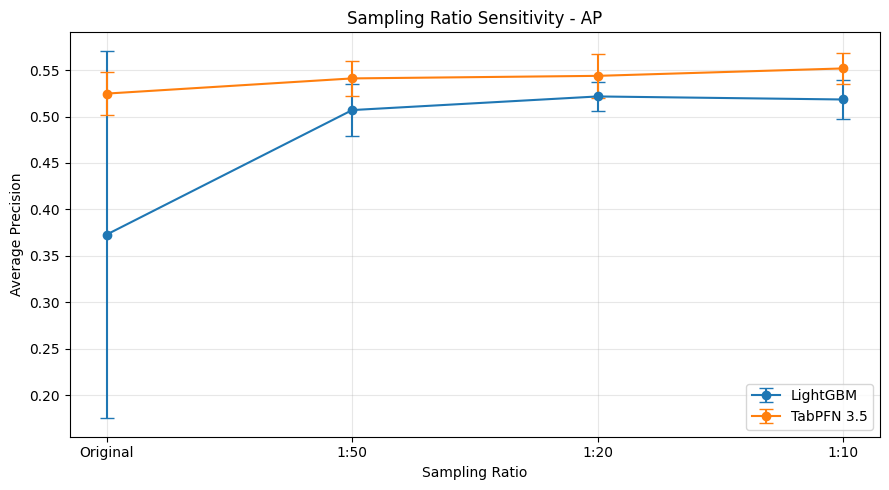

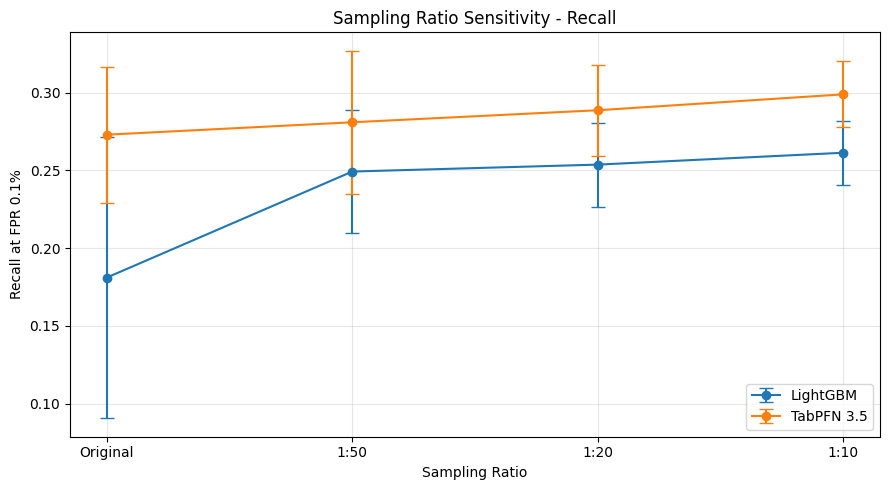

In [8]:
RATIO_ORDER = [
    'Original',
    '1:50',
    '1:20',
    '1:10'
]

for metric in ['AP', 'Recall']:

    plt.figure(figsize=(9, 5))

    for model_name in [
        'LightGBM',
        'TabPFN 3.5'
    ]:

        data = summary[
            summary['model'] == model_name
        ]

        data = data.set_index(
            'ratio'
        ).reindex(RATIO_ORDER)

        plt.errorbar(
            RATIO_ORDER,
            data[f'{metric}_mean'],
            yerr=data[f'{metric}_std'],
            marker='o',
            capsize=5,
            label=model_name
        )

    plt.xlabel('Sampling Ratio')

    plt.ylabel(
        'Average Precision'
        if metric == 'AP'
        else 'Recall at FPR 0.1%'
    )

    plt.title(f'Sampling Ratio Sensitivity - {metric}')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [9]:
assert (summary['runs'] == len(SEEDS)).all()
assert len(summary) == 8

summary['AP_rank'] = summary.groupby(
    'model'
)['AP_mean'].rank(
    ascending=False,
    method='average'
)

ranking = summary.groupby('ratio').agg(
    mean_rank=('AP_rank', 'mean'),
    mean_AP=('AP_mean', 'mean'),
    mean_Recall=('Recall_mean', 'mean')
).sort_values(
    ['mean_rank', 'mean_Recall'],
    ascending=[True, False]
)

display(ranking)

print('선정된 비율:', ranking.index[0])

,mean_rank,mean_AP,mean_Recall
ratio,,,
1:10,1.5,0.535035,0.280211
1:20,1.5,0.532676,0.271286
1:50,3.0,0.523973,0.265179
Original,4.0,0.448845,0.227070


선정된 비율: 1:10
